## Layer 4: Harness - Deep Agents, the top layer
We have reached the top of the stack. A **Deep Agent** takes the create_agent and wraps it in an opinionated harness, the kind of setup you would otherwise build yourself for serious, multi-step work.

Three things come built in. A planning tool, so the agent can write itself a todo list and work through it. A filesystem, so it can save and reread its working notes rather than holding everything in the conversation. And sub-agents, so it can hand a focused piece of work to a helper with its own clean context. You supply the intent, and the harness supplies the structure.

In [1]:
import os
from dotenv import load_dotenv
from langchain.chat_models import init_chat_model
from langchain_tavily import TavilySearch
from deepagents import create_deep_agent
from deepagents.backends import FilesystemBackend

from sympy.physics.units import temperature

load_dotenv(override=True)

# Define the tools for the agent to use
tools = [TavilySearch(max_results=1)]
NTFY_TOPIC_URL = os.getenv("NTFY_TOPIC_URL")

# -------------------- Clean all base urls --------------------
os.environ.pop("GROQ_BASE_URL", None)
os.environ.pop("GEMINI_BASE_URL", None)
os.environ.pop("OPENROUTER_BASE_URL", None)
os.environ.pop("GLM_Z_BASE_URL", None)
os.environ.pop("OLLAMA_BASE_URL", None)
os.environ.pop("OLLAMA_API_BASE", None)

'http://localhost:11434/v1'

### A research agent that plans, searches and writes
Here is our scenario. A company is getting ready to move its sales fleet to electric vehicles, and somebody has to do the homework first: how ready is the public charging network, and which charging providers could a fleet actually rely on? This is the kind of high level task that suits a Deep Agent: open ended enough to need a plan, several searches worth of research and a written briefing as the deliverable.

We point the agent's filesystem at a real `sandbox` folder, so anything it writes appears as a file on disk that we can open afterwards. The agent sees its filesystem at `/`, so when it reports writing to `/charging.md`, that appears as `charging.md` inside our sandbox folder.

It will write itself a todo list, search the web a few times and save a briefing to a file.

/Users/marcelogomesmarques/Projects/LLM/master_rag/.venv/lib/python3.13/site-packages/pyppeteer/us_keyboard_layout.py:73: SyntaxWarning: invalid escape sequence '\('
  'Digit9': {'keyCode': 57, 'code': 'Digit9', 'shiftKey': '\(', 'key': '9'},
/Users/marcelogomesmarques/Projects/LLM/master_rag/.venv/lib/python3.13/site-packages/pyppeteer/us_keyboard_layout.py:143: SyntaxWarning: invalid escape sequence '\<'
  'Comma': {'keyCode': 188, 'code': 'Comma', 'shiftKey': '\<', 'key': ','},
/Users/marcelogomesmarques/Projects/LLM/master_rag/.venv/lib/python3.13/site-packages/pyppeteer/us_keyboard_layout.py:247: SyntaxWarning: invalid escape sequence '\<'
  '<': {'keyCode': 188, 'key': '\<', 'code': 'Comma'},


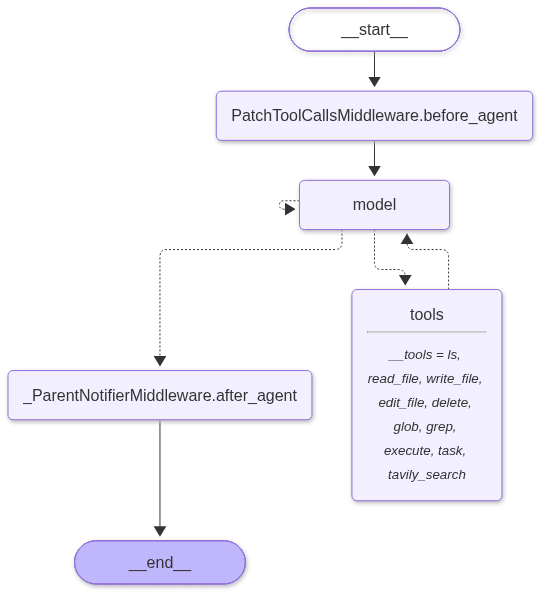

In [2]:
sandbox = os.path.abspath("sandbox")
os.makedirs(sandbox, exist_ok=True)

model = init_chat_model("groq:openai/gpt-oss-20b", temperature=0)

researcher = create_deep_agent(
    model=model,
    tools=tools,
    system_prompt=(
        "You are a research analyst. Plan your work with your todo tool, "
        "research with the search tool, and write your findings as a tidy markdown briefing to a file."
    ),
    backend=FilesystemBackend(root_dir=sandbox, virtual_mode=True),
)

# To see the created graph just call its variable as below:
researcher

In [3]:
brief = """
Our company is planning to move its sales fleet to electric vehicles.
Research the public EV charging landscape in the US: find out roughly how many public charging points there are,
and pick out two major charging networks a fleet could rely on.
Write a one page markdown briefing, with a heading and a short section for each, to the file charging.md.
"""

result = researcher.invoke({"messages": [{"role": "user", "content": brief}]})
print(result["messages"][-1].content)

The briefing has been written to **`/charging.md`**.  
You can review it with `read_file` or open the file directly.


Let us see how it worked. First, the tools it chose to call, which reveal the planning and the file writing.

Perform this same check in LagSmith as well.

In [4]:
tools_used = [tc["name"] for m in result["messages"] for tc in (getattr(m, "tool_calls", []) or [])]
print("Tools the agent called, in order:")
print(tools_used)

Tools the agent called, in order:
['tavily_search', 'tavily_search', 'write_file', 'read_file']


## Sub-agents: handing off focused work
A sub-agent is a helper the main agent can delegate to through its `task` tool. The helper runs with its own fresh context, does one job, and reports back a tidy result. This keeps the main agent's attention clear when a task has several independent pieces.

The charging briefing answered whether the fleet switch is feasible. The next question the company will ask is which car to buy, and that splits naturally into independent pieces: each candidate vehicle can be researched on its own. So we define a vehicle researcher sub-agent, and ask the main agent to compare two contenders for the fleet by delegating the research on each.

In [6]:
research_ev_instructions = """
You research one electric vehicle using the search tool and return three concise facts
that a fleet buyer would care about, such as price, range and charging.
"""

overall_instructions = """
You write comparison briefings for a company choosing electric vehicles for its sales fleet.
For each vehicle, delegate the research to your vehicle-researcher sub-agent,
then write a markdown comparison to a file, ending with a clear recommendation.
"""

research_subagent = {
    "name": "vehicle-researcher",
    "description": "Researches a single electric vehicle and returns a short list of facts about it.",
    "system_prompt": research_ev_instructions,
}

lead = create_deep_agent(
    model="openrouter:cohere/north-mini-code:free",
    tools=tools,
    system_prompt=overall_instructions,
    subagents=[research_subagent],
    backend=FilesystemBackend(root_dir=sandbox, virtual_mode=True),
)

#### Check the create deep agent graph

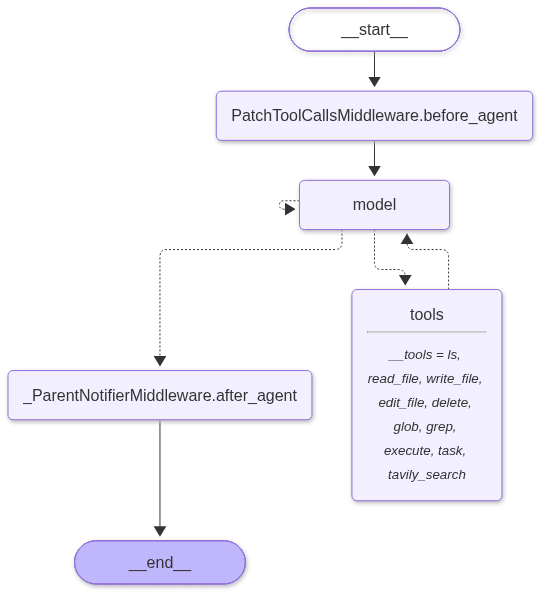

In [7]:
lead

In [8]:
mission = """
Compare the Tesla Model Y and the Ford Mustang Mach-E as candidates for our 100-car sales fleet.
Research each vehicle, then write a short markdown comparison with a recommendation to fleet.md.
"""

result = lead.invoke({"messages": [{"role": "user", "content": mission}]})

tools_used = [tc["name"] for m in result["messages"] for tc in (getattr(m, "tool_calls", []) or [])]
print("Tools the lead agent called:", tools_used)

Tools the lead agent called: ['task', 'task', 'write_file', 'read_file']


### Agent Skills
`deepagents` supports Anthropic's Agent Skills pattern, the same `SKILL.md` format that Claude Code uses.

A skill is just a folder containing a `SKILL.md` file: YAML frontmatter with a name and a description, followed by markdown instructions. Only the name and description go into the system prompt, and the agent reads the full file with its own `read_file` tool when it decides the skill is relevant. This is called progressive disclosure, and it means you can hand an agent a whole library of skills without flooding its context.

Anthropic publishes a library of skills in this format at [github.com/anthropics/skills](https://github.com/anthropics/skills), including the ones behind Claude's own document creation.

We have provided one in the sandbox: [sandbox/skills/fleet-slide/SKILL.md](sandbox/skills/fleet-slide/SKILL.md), the house style of Voltway Research, our fictional analyst brand, for turning a recommendation into a single slide. Open it and have a read before we hand it to an agent.

### A sub-agent that makes the slide with the Skill
Now for the payoff. We define a slide-maker sub-agent and give it two things the lead agent does not have: the fleet-slide skill, and a `create_slide` tool of its own. The tool wraps a slide template in `slide_kit.py` that handles the design work, with brand colors, logo and layout all taken care of, so the sub-agent's job is to read the briefing, distill the message, and follow the house style. Sub-agents can carry their own tools, models and skills, which is how you build a team of specialists around one lead agent.

In [11]:
from langchain_core.tools import tool
from slide_kit import build_slide

@tool
def create_slide(title: str, key_points: list[str], recommendation: str) -> str:
    """Create a one-slide PowerPoint in the Voltway Research house style, saved as fleet.pptx."""
    build_slide(title, key_points, recommendation, os.path.join(sandbox, "fleet.pptx"))
    return "Saved the slide to /fleet.pptx"

slide_maker = {
    "name": "slide-maker",
    "description": "Turns a finished recommendation into a one-slide PowerPoint deck.",
    "system_prompt": "You turn research recommendations into slides, following your fleet-slide skill.",
    "tools": [create_slide],
    "skills": ["/skills/"],
}

presenter = create_deep_agent(
    model=model,
    subagents=[slide_maker],
    system_prompt="You prepare research for presentation by delegating to your slide-maker sub-agent.",
    backend=FilesystemBackend(root_dir=sandbox, virtual_mode=True),
)

result = presenter.invoke({"messages": [{"role": "user", "content":
    "Read fleet.md and have a one-slide deck made of its recommendation."}]})
print(result["messages"][-1].content)

```markdown
# Electric Vehicle Fleet Recommendation

**Primary Choice:** Ford Mustang Mach‑E  
**Secondary Choice:** Tesla Model Y

**Key Reasons**

- Base price $37,795 vs Tesla $46,380  
- Plug & Charge for hassle‑free fleet charging  
- 5‑star NHTSA safety rating  
- Lower 5‑year maintenance cost for Tesla  
- Mustang brand appeal for sales teams

**Quick Comparison**

| Feature          | Ford Mustang Mach‑E | Tesla Model Y |
|------------------|---------------------|---------------|
| Starting Price   | $37,795             | $46,380       |
| Plug & Charge    | Yes                 | No            |
| 5‑star NHTSA     | Yes                 | Yes           |
| 5‑Year Maintenance | $65,533‑$72,882   | $3,065        |
| Warranty         | 3‑yr/36k & 5‑yr/60k | 8‑yr/100k     |

🚗
```


result = presenter.invoke({"messages": [{"role": "user", "content":
    "Read fleet.md and have a one-slide deck made of its recommendation."}]})
print(result["messages"][-1].content)